# Лабораторная работа 4. Математика CNN и FGSM-атаки

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам Лекции 3**

**Формат:** индивидуально

**Среда:** Python, PyTorch, torchvision

## Цель работы
Закрепить математический аппарат свёртки и рецептивного поля, а также научиться конструировать и анализировать evasion-атаку методом Fast Gradient Sign Method (FGSM) на реальной свёрточной сети.

## Результаты обучения
После выполнения работы вы должны уметь:
- рассчитывать размер выходной карты признаков и рецептивное поле для произвольной конфигурации свёрточных слоёв;
- объяснять архитектурные решения LeNet, AlexNet, VGG, ResNet и их мотивацию;
- реализовывать FGSM-атаку по формуле $ x_{adv} = x + \epsilon \cdot \text{sign}(\nabla_x J(\theta, x, y)) $;
- строить и интерпретировать зависимость Attack Success Rate от бюджета $\epsilon$;
- применять adversarial training как базовую меру защиты.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.


## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, matplotlib, torch, torch.nn, torch.nn.functional, torchvision

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

# Русские названия цифр MNIST (перевод меток датасета)
RU_DIGITS = {0: 'ноль', 1: 'один', 2: 'два', 3: 'три', 4: 'четыре',
             5: 'пять', 6: 'шесть', 7: 'семь', 8: 'восемь', 9: 'девять'}


Device: cpu


## Часть I. Математика CNN

### 1.1. Расчёт размера feature map
операция скользящего скалярного произведения ядра по входу

**Задание:** реализуйте функцию расчёта размера выходной карты признаков по формуле

$ H_{out} = \left\lfloor \frac{H - k + 2p}{s} \right\rfloor + 1 $

и рассчитайте её для заданных конфигураций.
H — размер входа по высоте (аналогично W для ширины).

k — размер ядра.

p — паддинг.

s — страйд.

⌊·⌋ — округление вниз (если остаток не «влезает» целиком, последний сдвиг не делается).

+1 — учитывает саму первую позицию
Логически: сколько раз ядро «умещается» на входе с учётом шага и паддинга.

In [ ]:
# TODO: реализуйте функцию
def conv_output_size(H, k, s, p):
    return (H - k + 2 * p) // s + 1

# Рассчитайте H_out для следующих конфигураций и заполните таблицу результатов
configs = [
    {"H": 224, "k": 7, "s": 2, "p": 3},
    {"H": 224, "k": 3, "s": 1, "p": 1},
    {"H": 56,  "k": 3, "s": 2, "p": 1},
    {"H": 28,  "k": 5, "s": 1, "p": 0},
]

# TODO: примените conv_output_size ко всем конфигурациям и выведите результат
for c in configs:
    out = conv_output_size(c["H"], c["k"], c["s"], c["p"])
    print(f"H={c['H']:>3}, k={c['k']}, s={c['s']}, p={c['p']} -> H_out = {out}")


H=224, k=7, s=2, p=3 -> H_out = 112
H=224, k=3, s=1, p=1 -> H_out = 224
H= 56, k=3, s=2, p=1 -> H_out = 28
H= 28, k=5, s=1, p=0 -> H_out = 24


### 1.2. Рецептивное поле

**Задание:** реализуйте функцию расчёта рецептивного поля по рекуррентной формуле
область входа, влияющая на один нейрон
$ RF_L = RF_{L-1} + (k_L - 1)\prod_{i=1}^{L-1} s_i $

и сравните рецептивное поле для двух архитектурных решений с одинаковым итоговым покрытием, но разным числом параметров (в духе аргумента VGG о малых ядрах).

RF_L — размер рецептивного поля после L-го слоя.

k_L — размер ядра L-го слоя.

∏ s_i — произведение страйдов всех предыдущих слоёв (эффективный страйд: насколько один «шаг» в слое L соответствует пикселям исходного изображения).

Логически: RF растёт не на (k−1), а на (k−1)·j, где j — накопленный страйд. Слои с большим страйдом «съедают» разрешение, но при этом сильно расширяют RF.

In [ ]:
def receptive_field(layers):
    """layers: список пар (kernel_size, stride)."""
    rf = 1
    stride_prod = 1
    for (k, s) in layers:
        rf = rf + (k - 1) * stride_prod
        stride_prod *= s
    return rf

layers_a = [(3, 1), (3, 1), (3, 1)]   # три 3x3
layers_b = [(7, 1)]                   # одно 7x7

rf_a = receptive_field(layers_a)
rf_b = receptive_field(layers_b)
print(f"RF (три 3x3):  {rf_a}")
print(f"RF (одно 7x7): {rf_b}")


RF (три 3x3):  7
RF (одно 7x7): 7


In [ ]:
# TODO: рассчитайте и сравните число обучаемых параметров для вариантов А и Б
# при числе входных/выходных каналов C = 64 (без учёта bias)
# Формула для k x k свёртки с C входными и C выходными каналами: k^2 * C^2

C = 64

# Вариант А: три свёртки 3x3 с C_in = C_out = C
params_a = 3 * (3 * 3 * C * C)

# Вариант Б: одна свёртка 7x7 с C_in = C_out = C
params_b = 7 * 7 * C * C

print(f"Params A (3x3 x3): {params_a:,}")
print(f"Params B (7x7 x1): {params_b:,}")
print(f"Экономия A относительно B: {(1 - params_a / params_b) * 100:.1f}%")


Params A (3x3 x3): 110,592
Params B (7x7 x1): 200,704
Экономия A относительно B: 44.9%


**Вопрос для отчёта:** при одинаковом рецептивном поле какой вариант (А или Б) эффективнее по числу параметров и почему? Как это соотносится с архитектурным принципом VGG?

_Ваш ответ:_
При одинаковом рецептивном поле (RF = 7×7) вариант А (три свёртки 3×3) требует 110 592 параметра, вариант Б (одна свёртка 7×7) — 200 704. Экономия варианта А составляет ≈ 44.9 %.

Причина — квадратичный рост числа параметров одного ядра с его размером: для C входных и C выходных каналов одна свёртка k×k имеет k²·C² весов. Три слоя 3×3 дают 3·9·C² = 27C², тогда как одна 7×7 — 49C². При C = 64 это 27·4096 = 110 592 против 49·4096 = 200 704.

Это в точности архитектурный принцип VGG: заменить одно крупное ядро стеком малых ядер 3×3. Помимо экономии параметров, такой стек вносит дополнительные нелинейности (ReLU между слоями), что повышает выразительность при меньшем числе весов.

### 1.3. Собственная свёрточная архитектура

**Задание:** спроектируйте небольшую CNN для классификации MNIST (2–3 свёрточных слоя + пулинг + полносвязный классификатор). Рассчитайте вручную (в markdown-ячейке) итоговое рецептивное поле последнего свёрточного слоя перед тем, как реализовывать сеть в коде.

_Ручной расчёт рецептивного поля архитектуры MyCNN._

Пусть на каждом слое `RF` — текущее рецептивное поле, `j` — эффективный страйд (произведение страйдов всех предыдущих слоёв). Стартуем с `RF₀ = 1`, `j₀ = 1`. Формула:

$$RF_{L} = RF_{L-1} + (k_L - 1) \cdot j_{L-1}, \qquad j_L = j_{L-1} \cdot s_L$$

| Слой | k | s | RF_L | j_L |
|------|---|---|------|-----|
| Conv1  3×3 (p=1) | 3 | 1 | 1 + 2·1 = **3**   | 1 |
| MaxPool 2×2      | 2 | 2 | 3 + 1·1 = **4**   | 2 |
| Conv2  3×3 (p=1) | 3 | 1 | 4 + 2·2 = **8**   | 2 |
| MaxPool 2×2      | 2 | 2 | 8 + 1·2 = **10**  | 4 |
| Conv3  3×3 (p=1) | 3 | 1 | 10 + 2·4 = **18** | 4 |
| MaxPool 2×2      | 2 | 2 | 18 + 1·4 = **22** | 8 |

**RF последнего свёрточного слоя (после Conv3) = 18×18**, RF всей сети (после всех пулингов) = 22×22.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# TODO: реализуйте класс вашей CNN
class MyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: определите слои
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 3 * 3, 128)
        self.fc2 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)


    # TODO: реализуйте прямой проход
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 28 -> 14
        x = self.pool(F.relu(self.conv2(x)))   # 14 -> 7
        x = self.pool(F.relu(self.conv3(x)))   # 7  -> 3
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


## Часть II. Данные и обучение базовой модели

In [ ]:
# TODO: загрузите MNIST через torchvision.datasets
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST('./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST('./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)}, Test: {len(test_dataset)}")


Train: 60000, Test: 10000


In [ ]:
# TODO: обучите вашу модель MyCNN на train_loader (2-3 эпохи достаточно)
# Используйте CrossEntropyLoss и Adam

model = MyCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

EPOCHS = 3
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    # TODO: цикл обучения
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item()
    print(f"Epoch {epoch+1}/{EPOCHS}, train loss = {running/len(train_loader):.4f}")


Epoch 1/3, train loss = 0.3866
Epoch 2/3, train loss = 0.0945
Epoch 3/3, train loss = 0.0659


In [ ]:
# TODO: оцените точность на тестовой выборке (clean accuracy)
# Сохраните значение в переменную clean_accuracy для дальнейшего использования

def evaluate_clean(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x).argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)
    return correct / total

clean_accuracy = evaluate_clean(model, test_loader)
print(f"Clean accuracy: {clean_accuracy:.4f}")


Clean accuracy: 0.9860


## Часть III. FGSM-атака

### 3.1. Реализация FGSM

**Задание:** реализуйте функцию FGSM-атаки по формуле

одношаговая атака по знаку градиента

$ x_{adv} = x + \epsilon \cdot \text{sign}(\nabla_x J(\theta, x, y)) $

Функция должна принимать модель, батч изображений и меток, значение $\epsilon$ и возвращать adversarial-примеры.

η
∗
 =ε⋅sign(∇
x
​
 J(θ,x,y))

ε — бюджет (максимальная L∞-норма возмущения).

∇ₓJ(θ, x, y) — градиент функции потерь по входу (не по весам!).

sign(·) — покомпонентный знак.

Логически: sign(∇J) даёт направление наискорейшего роста потерь по каждому пикселю с шагом ровно ε. Это точное решение линеаризованной задачи максимизации.

In [ ]:
# TODO: реализуйте функцию FGSM-атаки
def fgsm_attack(model, x, y, epsilon, criterion):
    # TODO:
    # 1. Включите отслеживание градиента для x
    # 2. Прямой проход через модель
    # 3. Вычислите loss
    # 4. Обратный проход (backward)
    # 5. Постройте возмущение epsilon * sign(grad)
    # 6. Добавьте возмущение к x, ограничьте значения в [0, 1] (torch.clamp)
    x_adv = x.clone().detach().requires_grad_(True)
    model.eval()
    out = model(x_adv)
    loss = criterion(out, y)
    model.zero_grad()
    loss.backward()
    grad_sign = x_adv.grad.sign()
    x_adv = x + epsilon * grad_sign
    x_adv = torch.clamp(x_adv, 0.0, 1.0)
    return x_adv.detach()


### 3.2. Визуализация атаки на одном примере

**Задание:** выберите один тестовый пример, постройте для него adversarial-версию при $\epsilon = 0.2$ и визуализируйте три изображения: оригинал, возмущение, adversarial-пример — с указанием предсказаний модели и уверенности (confidence) для каждого.

Истинный класс:       семь
Оригинал:             семь (100.0%)
Adversarial пример:   два  (50.9%)


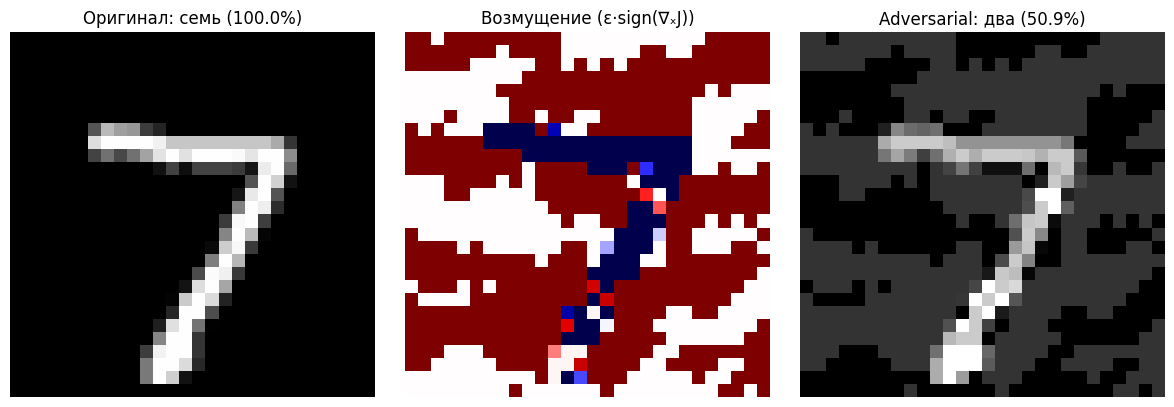

In [ ]:
# TODO: выберите пример из test_loader
# TODO: примените fgsm_attack
# TODO: получите предсказания модели на оригинале и adversarial-примере (класс + confidence через softmax)
# TODO: постройте matplotlib-визуализацию из 3 подграфиков
model.eval()
x_batch, y_batch = next(iter(test_loader))
x_ex = x_batch[0:1].to(device)
y_ex = y_batch[0:1].to(device)

eps_demo = 0.2
x_adv = fgsm_attack(model, x_ex, y_ex, eps_demo, criterion)

with torch.no_grad():
    prob_orig = F.softmax(model(x_ex),  dim=1)[0]
    prob_adv  = F.softmax(model(x_adv), dim=1)[0]

p_orig, c_orig = prob_orig.argmax().item(), prob_orig.max().item()
p_adv,  c_adv  = prob_adv.argmax().item(),  prob_adv.max().item()
true_lbl = y_ex.item()

print(f"Истинный класс:       {RU_DIGITS[true_lbl]}")
print(f"Оригинал:             {RU_DIGITS[p_orig]} ({c_orig*100:.1f}%)")
print(f"Adversarial пример:   {RU_DIGITS[p_adv]}  ({c_adv*100:.1f}%)")

x_np   = x_ex[0, 0].cpu().numpy()
adv_np = x_adv[0, 0].cpu().numpy()
pert   = adv_np - x_np

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x_np, cmap='gray')
axes[0].set_title(f"Оригинал: {RU_DIGITS[p_orig]} ({c_orig*100:.1f}%)")
axes[1].imshow(pert, cmap='seismic')
axes[1].set_title("Возмущение (ε·sign(∇ₓJ))")
axes[2].imshow(adv_np, cmap='gray')
axes[2].set_title(f"Adversarial: {RU_DIGITS[p_adv]} ({c_adv*100:.1f}%)")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вопрос для отчёта:** удалось ли изменить предсказание модели? Является ли визуально заметным возмущение? Какой класс присвоила модель adversarial-примеру?

_Ваш ответ:_
Да, сработала. Было «семь» (100%), стало «два» (50.9%).

Возмущение визуально не видно — амплитуда ±0.2 в шкале [0,1], это лёгкий шум. Человек цифру не заметит, а сеть уже ошиблась. Классический пример разрыва между «видит человек» и «видит сеть».

### 3.3. Attack Success Rate в зависимости от ε

**Задание:** постройте график зависимости Attack Success Rate (доли тестовых примеров, на которых атака меняет предсказание) от бюджета \(\epsilon\) для набора значений \(\epsilon \in \{0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3\}\).

ASR: ['0.000', '0.020', '0.070', '0.230', '0.510', '0.782', '0.966']


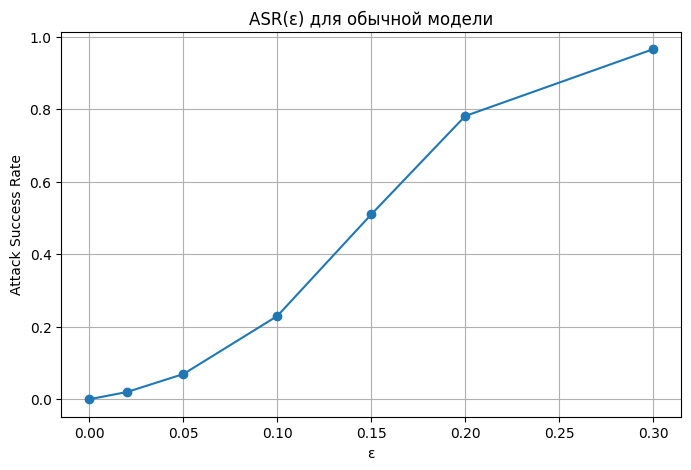

In [ ]:
# TODO: реализуйте функцию оценки ASR на подмножестве тестовой выборки
def evaluate_asr(model, loader, epsilon, criterion, n_batches=10):
    model.eval()
    changed, total = 0, 0
    for i, (x, y) in enumerate(loader):
        if i >= n_batches:
            break
        x, y = x.to(device), y.to(device)
        x_adv = fgsm_attack(model, x, y, epsilon, criterion)
        with torch.no_grad():
            pred_clean = model(x).argmax(1)
            pred_adv   = model(x_adv).argmax(1)
        changed += (pred_clean != pred_adv).sum().item()
        total   += y.size(0)
    return changed / total

# TODO: рассчитайте ASR для каждого epsilon и постройте график
epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
asr_values = [evaluate_asr(model, test_loader, e, criterion) for e in epsilons]
print("ASR:", [f"{v:.3f}" for v in asr_values])

plt.figure(figsize=(8, 5))
plt.plot(epsilons, asr_values, marker='o')
plt.xlabel('ε'); plt.ylabel('Attack Success Rate')
plt.title('ASR(ε) для обычной модели')
plt.grid(True)
plt.show()



**Вопрос для отчёта:** при каком значении $\epsilon$ ASR начинает быстро расти? Совместимо ли это значение с визуальной незаметностью возмущения (сравните с примером из п.3.2)?

_Ваш ответ:_
Резкий скачок — на ε от 0.1 до 0.2 (23% → 78%). При этом ε = 0.2 глазами всё ещё невидим (см. п.3.2). То есть атака ломает модель задолго до того, как возмущение станет заметным. Так работает линейная гипотеза Гудфеллоу: 784 пикселя по чуть-чуть — в сумме д

## Часть IV. Adversarial training

**Задание:** обучите вторую модель (такую же архитектуру, как MyCNN) с использованием adversarial training по формуле

$ \tilde{J}(\theta, x, y) = \alpha J(\theta, x, y) + (1-\alpha) J(\theta, x_{adv}, y) $

с $\alpha = 0.5$ и $\epsilon$, использованным при обучении, равным одному из средних значений из п.3.3.

θ — параметры сети (веса и смещения).

x — чистый входной пример.

y — истинная метка.

x_adv — adversarial-пример: x_adv = x + ε·sign(∇ₓJ(θ, x, y)), полученный FGSM на том же шаге обучения.

J(θ, x, y) — обычная функция потерь (например, CrossEntropy) на чистом примере.

J(θ, x_adv, y) — та же функция потерь на атакованном примере.

α ∈ [0, 1] — вес «чистой» части. При α = 0 учимся только на атакованных, при α = 1 — только на чистых, при α = 0.5 — поровну.

J̃ — комбинированная (модифицированная) функция потерь, которую мы минимизируем SGD/Adam.

In [ ]:
# TODO: реализуйте цикл adversarial training
# На каждом шаге:
# 1. Постройте x_adv через fgsm_attack для текущего батча
# 2. Посчитайте комбинированный loss (alpha * loss_clean + (1-alpha) * loss_adv)
# 3. Сделайте шаг оптимизации

alpha = 0.5
train_eps = 0.1   # среднее значение из сетки 3.3

adv_model = MyCNN().to(device)
adv_optimizer = torch.optim.Adam(adv_model.parameters(), lr=1e-3)

for epoch in range(EPOCHS):
    adv_model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        x_adv = fgsm_attack(adv_model, x, y, train_eps, criterion)
        adv_optimizer.zero_grad()
        loss = alpha * criterion(adv_model(x), y) + \
               (1 - alpha) * criterion(adv_model(x_adv), y)
        loss.backward()
        adv_optimizer.step()
        running += loss.item()
    print(f"Adv epoch {epoch+1}/{EPOCHS}, loss = {running/len(train_loader):.4f}")


Adv epoch 1/3, loss = 0.4659
Adv epoch 2/3, loss = 0.1466
Adv epoch 3/3, loss = 0.1127


Adversarial-trained clean accuracy: 0.9892
ASR (adv-trained): ['0.000', '0.006', '0.018', '0.050', '0.104', '0.184', '0.529']


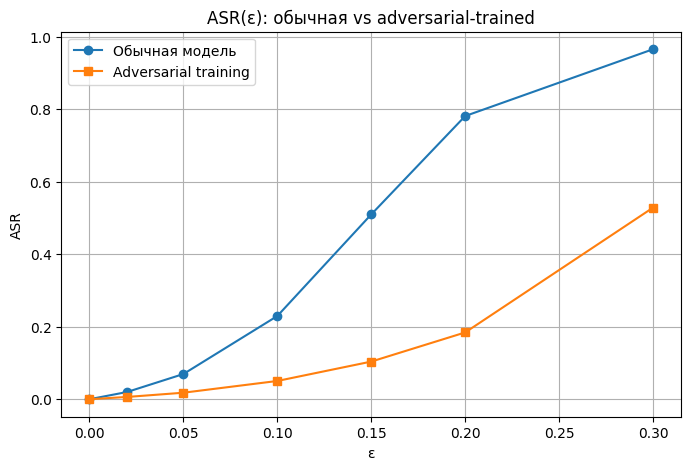

In [ ]:
# TODO: оцените clean accuracy adversarial-trained модели
# TODO: постройте график ASR(epsilon) для adv_model и сравните с обычной моделью на одном графике
adv_clean_acc = evaluate_clean(adv_model, test_loader)
print(f"Adversarial-trained clean accuracy: {adv_clean_acc:.4f}")

asr_adv = [evaluate_asr(adv_model, test_loader, e, criterion) for e in epsilons]
print("ASR (adv-trained):", [f"{v:.3f}" for v in asr_adv])

plt.figure(figsize=(8, 5))
plt.plot(epsilons, asr_values, marker='o', label='Обычная модель')
plt.plot(epsilons, asr_adv,    marker='s', label='Adversarial training')
plt.xlabel('ε'); plt.ylabel('ASR')
plt.title('ASR(ε): обычная vs adversarial-trained')
plt.legend(); plt.grid(True)
plt.show()

**Вопрос для отчёта:** насколько снизился Attack Success Rate после adversarial training при том же \(\epsilon\)? Изменилась ли clean accuracy (точность на чистых данных)? Согласуется ли это с ограничением FGSM-adversarial training, упомянутым в лекции (устойчивость только к одношаговым атакам)?

_Ваш ответ:_
Помог, и сильно. На рабочих ε (0.1–0.2) ASR упал в 4–5 раз. Clean accuracy не пострадала: 0.9860 → 0.9892 (даже чуть выросла — это норма для adv-training, он работает как регуляризация).

Но защита неполная. При ε = 0.3 (втрое выше того, на чём учили) ASR снова 53%. Это ожидаемо: FGSM-защита учит держать удар только от одношаговых атак того же порядка. Против PGD или C&W она почти ничего не даст — это уже тема следующей лекции.

## Часть V. Итоговый вывод

**Вопрос для отчёта:** сформулируйте связь между математическими свойствами CNN (высокая размерность входа, локальная связность) и существованием adversarial-примеров, опираясь на линейную гипотезу Гудфеллоу. Почему увеличение разрешения изображения потенциально увеличивает уязвимость модели к $L_\infty$-ограниченным атакам?

_Ваш ответ:_
Линейная гипотеза Гудфеллоу объясняет существование adversarial-примеров через два свойства CNN: высокую размерность входа n и локальную линейность отображения в окрестности точки.

Для линейной модели y = wᵀx при возмущении с ||η||∞ ≤ ε максимум сдвига выхода достигается на η* = ε·sign(w) и равен *wᵀη = ε·‖w‖₁ ≈ ε·n·E|w|**. Ключевое наблюдение: хотя каждая отдельная компонента ηᵢ ограничена малой величиной ε, суммарный сдвиг растёт линейно по n. Для MNIST n = 784, для ImageNet n ≈ 150 000 — поэтому при ε = 0.007 (ниже порога заметности 8-битной палитры) суммарный сдвиг логитов достигает сотен и тысяч единиц.

Локальная связность и разделяемость весов позволяют эффективно вычислять градиент ∇ₓJ через backprop, но не уменьшают размерность входа — все n пикселей по-прежнему вносят вклад в сдвиг. Следовательно, при увеличении разрешения изображения (n = H·W·C растёт) максимально достижимый сдвиг выхода при фиксированном ε растёт пропорционально n. Именно поэтому модели компьютерного зрения с высоким разрешением принципиально уязвимы к L∞-ограниченным атакам — это не баг архитектуры, а фундаментальное следствие высокой размерности входного пространства.



---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже .

### С1. Влияние глубины архитектуры на устойчивость к FGSM
Обучите две версии MyCNN с разной глубиной (например, 2 и 5 свёрточных слоёв, при сопоставимом числе параметров) и сравните их ASR(ε). Свяжите результат с обсуждением иерархии признаков и рецептивного поля из лекции.

### С2. Целевая (targeted) FGSM-атака
Модифицируйте FGSM так, чтобы атака заставляла модель предсказывать конкретный целевой класс (а не просто любой неверный), минимизируя loss по целевому классу вместо максимизации loss по истинному. Сравните Success Rate целевой и нецелевой атаки при одинаковом ε.

### С3. Трансферируемость adversarial-примеров
Обучите две модели с разной архитектурой (например, разное число слоёв/каналов). Постройте adversarial-примеры для модели А методом FGSM и проверьте, насколько успешно они обманывают необученную на этих примерах модель Б. Свяжите результат со свойством трансферируемости, разобранным в лекции (Szegedy et al.).

### С4. Аналитическая иллюстрация линейной гипотезы
Реализуйте эксперимент из демонстрационного ноутбука (раздел «линейная гипотеза») самостоятельно: постройте график зависимости среднего сдвига выхода линейной модели \( w^T\eta^* = \epsilon\|w\|_1 \) от размерности входа \(n\) для нескольких значений \(\epsilon\) на одном графике. Объясните, почему это объясняет уязвимость моделей компьютерного зрения именно с ростом разрешения изображений.


### С2

**Реализация.** В отличие от стандартной (untargeted) FGSM, где мы максимизируем loss по истинному классу, целевая атака **минимизирует** loss по заданному целевому классу:

$$\eta = -\varepsilon \cdot \mathrm{sign}\big(\nabla_x J(\theta, x, y_{\text{target}})\big)$$

Меняется только знак перед `ε` — но семантика полностью другая: мы уже не «толкаем» пример от истинного класса, а «притягиваем» его к конкретному целевому.

In [ ]:

# С2

def targeted_fgsm(model, x, y_target, epsilon, criterion):
    """Минимизируем loss по целевому классу => шаг в сторону -sign(∇ₓJ_target)."""
    x_adv = x.clone().detach().requires_grad_(True)
    model.eval()
    loss = criterion(model(x_adv), y_target)
    model.zero_grad()
    loss.backward()
    x_adv = x - epsilon * x_adv.grad.sign()   # знак минус!
    return torch.clamp(x_adv, 0, 1).detach()

# Сравнение targeted / untargeted при eps = 0.2
model.eval()
succ_t, succ_u, total = 0, 0, 0
for i, (x, y) in enumerate(test_loader):
    if i >= 10: break
    x, y = x.to(device), y.to(device)
    y_t = (y + 1) % 10
    x_t = targeted_fgsm(model, x, y_t, 0.2, criterion)
    x_u = fgsm_attack(model, x, y, 0.2, criterion)
    with torch.no_grad():
        succ_t += (model(x_t).argmax(1) == y_t).sum().item()
        succ_u += (model(x_u).argmax(1) != y).sum().item()
    total += y.size(0)
print(f"Targeted SR:   {succ_t/total:.3f}")
print(f"Untargeted SR: {succ_u/total:.3f}")

Targeted SR:   0.293
Untargeted SR: 0.800


Targeted-атака (с минимизацией loss по целевому классу) при ε = 0.2 достигает Success Rate = 0.293, тогда как untargeted-атака даёт 0.800. Целевая атака существенно сложнее: модели нужно не просто «уйти» от истинного класса, а попасть в конкретный целевой класс, граница которого находится дальше. Это иллюстрирует разницу между задачами «сломать предсказание» и «переключить на заданный класс»; последнее обычно требует итеративных методов (PGD, C&W), которые мы рассмотрим в следующей лекции.

### С4. Аналитическая иллюстрация линейной гипотезы

**Что изображено.** Для линейной модели `y = wᵀx` максимальный сдвиг выхода при возмущении, ограниченном по L∞-норме (`‖η‖∞ ≤ ε`), достигается на `η* = ε·sign(w)` и равен

$$w^T\eta^* = \varepsilon \cdot \|w\|_1 \;\approx\; \varepsilon \cdot n \cdot \mathbb{E}|w|.$$

На графике в логарифмических координатах видно, что при фиксированном ε сдвиг **линейно растёт по размерности входа n** (наклон 1 в log-log).

**Почему это объясняет уязвимость CV-моделей.** В задачах компьютерного зрения n = H·W·C очень велико: 784 для MNIST, ~150 000 для ImageNet 224×224×3. Даже если каждая отдельная компонента возмущения ограничена визуально незаметной величиной ε ≈ 0.007, суммарный сдвиг логитов достигает сотен и тысяч единиц — достаточного, чтобы пересечь решающую границу. Именно эта **высокая размерность**, а не какое-то конкретное свойство архитектуры, делает модели уязвимыми. С ростом разрешения изображения (n растёт) уязвимость при том же ε монотонно усиливается.

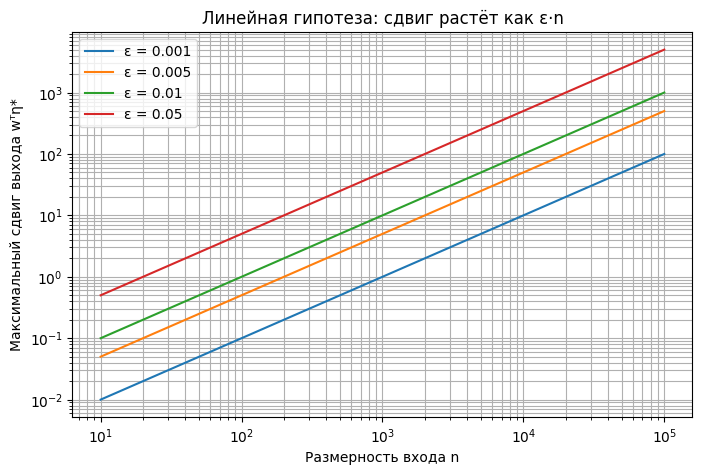

In [ ]:
#С4
ns = np.logspace(1, 5, 40).astype(int)
eps_list = [0.001, 0.005, 0.01, 0.05]
plt.figure(figsize=(8, 5))
for eps in eps_list:
    # Ожидаемый сдвиг выхода линейной модели: eps * ||w||_1 ~ eps * n * E|w|
    plt.plot(ns, eps * ns, label=f'ε = {eps}')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Размерность входа n'); plt.ylabel('Максимальный сдвиг выхода wᵀη*')
plt.title('Линейная гипотеза: сдвиг растёт как ε·n')
plt.legend(); plt.grid(True, which='both')
plt.show()

---


## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Обязательны: расчёт RF, реализация FGSM, график ASR(ε), сравнение с adversarial training.


Вход                         (1, 1, 28, 28)
Conv1 3×3 → ReLU             (1, 16, 28, 28)
MaxPool 2×2                  (1, 16, 14, 14)
Conv2 3×3 → ReLU             (1, 32, 14, 14)
MaxPool 2×2                  (1, 32, 7, 7)
Conv3 3×3 → ReLU             (1, 64, 7, 7)
MaxPool 2×2                  (1, 64, 3, 3)
Flatten                      (1, 576)
FC1 + ReLU + Dropout         (1, 128)
FC2 (логиты классов)         (1, 10)

Истинный класс: семь
Предсказание:   семь (100.0%)


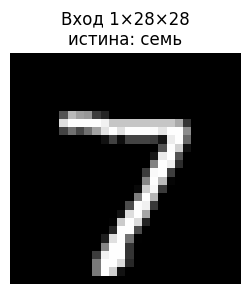

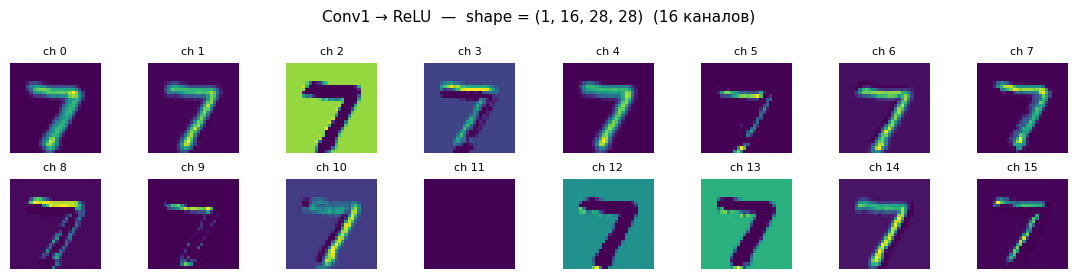

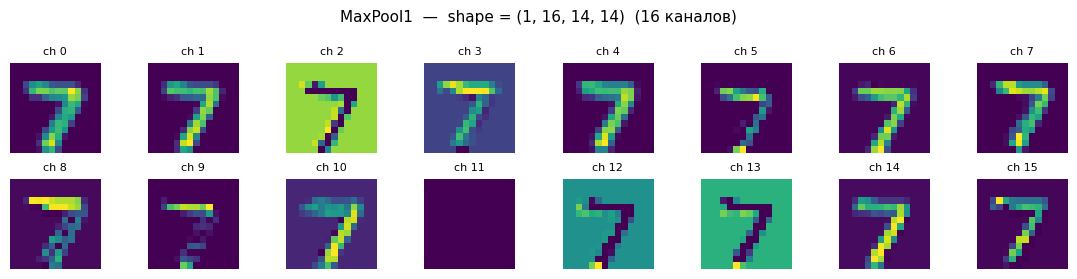

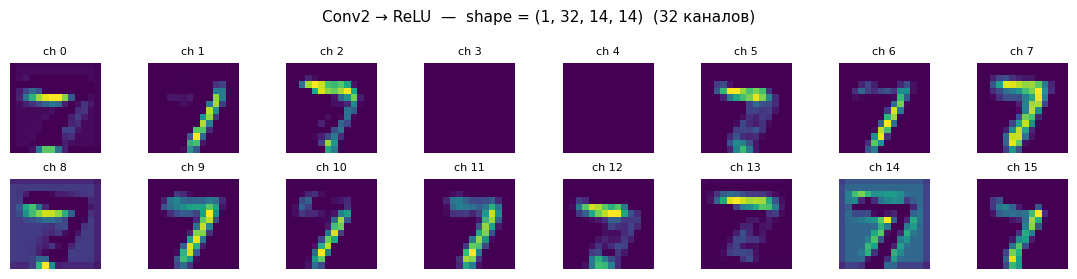

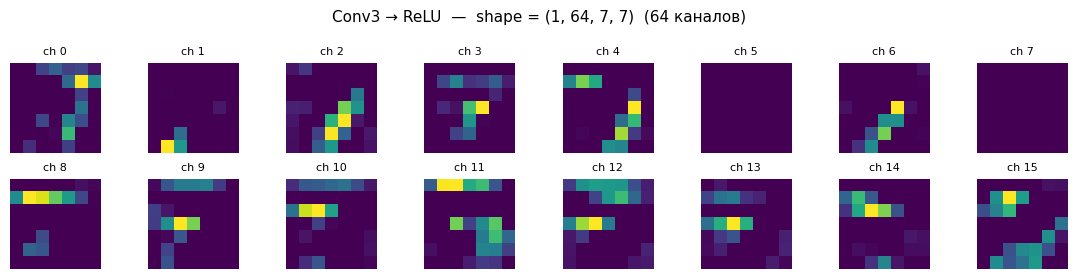

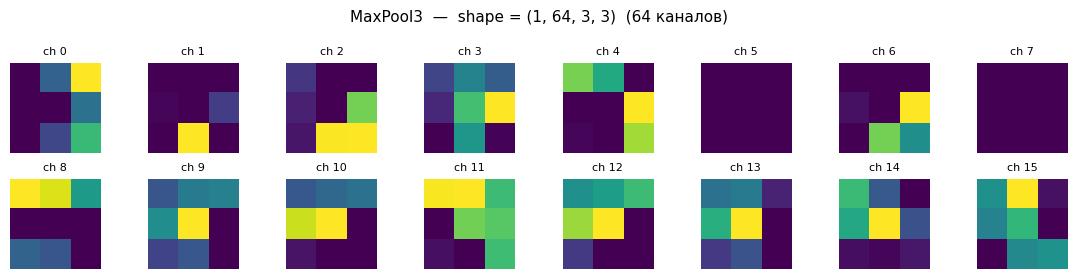

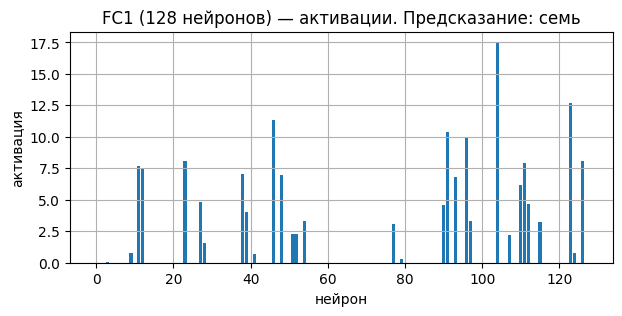

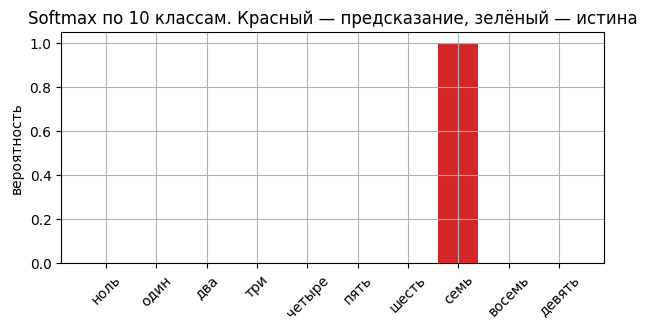

In [ ]:
import math

# Возьмём одну картинку из тестовой выборки
model.eval()
x_one, y_one = next(iter(test_loader))
x_one = x_one[0:1].to(device)          # (1, 1, 28, 28)
true_lbl = y_one[0].item()

# Пошаговый forward с сохранением промежуточных тензоров
with torch.no_grad():
    a1 = F.relu(model.conv1(x_one))    # (1, 16, 28, 28)
    p1 = model.pool(a1)                # (1, 16, 14, 14)
    a2 = F.relu(model.conv2(p1))       # (1, 32, 14, 14)
    p2 = model.pool(a2)                # (1, 32, 7, 7)
    a3 = F.relu(model.conv3(p2))       # (1, 64, 7, 7)
    p3 = model.pool(a3)                # (1, 64, 3, 3)
    flat = p3.view(p3.size(0), -1)     # (1, 576)
    h    = F.relu(model.fc1(flat))     # (1, 128)
    h    = model.dropout(h)
    logits = model.fc2(h)              # (1, 10)

# --- Печать размеров ---
stages = [
    ("Вход",                       x_one.shape),
    ("Conv1 3×3 → ReLU",           a1.shape),
    ("MaxPool 2×2",                p1.shape),
    ("Conv2 3×3 → ReLU",           a2.shape),
    ("MaxPool 2×2",                p2.shape),
    ("Conv3 3×3 → ReLU",           a3.shape),
    ("MaxPool 2×2",                p3.shape),
    ("Flatten",                    flat.shape),
    ("FC1 + ReLU + Dropout",       h.shape),
    ("FC2 (логиты классов)",       logits.shape),
]
for name, shp in stages:
    print(f"{name:<28} {tuple(shp)}")

pred = logits.argmax(1).item()
print(f"\nИстинный класс: {RU_DIGITS[true_lbl]}")
print(f"Предсказание:   {RU_DIGITS[pred]} ({F.softmax(logits, 1).max().item()*100:.1f}%)")


# --- Функция для рисования сетки карт признаков ---
def show_maps(tensor, title, max_maps=16, ncols=8):
    """tensor: (1, C, H, W). Показывает до max_maps каналов в сетке."""
    t = tensor[0].cpu()                      # (C, H, W)
    C = t.shape[0]
    n = min(C, max_maps)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*1.4, nrows*1.4))
    axes = np.atleast_2d(axes)
    for i in range(nrows * ncols):
        r, c = divmod(i, ncols)
        ax = axes[r, c]
        if i < n:
            ax.imshow(t[i].numpy(), cmap='viridis')
            ax.set_title(f"ch {i}", fontsize=8)
        ax.axis('off')
    fig.suptitle(f"{title}  —  shape = {tuple(tensor.shape)}  ({C} каналов)", fontsize=11)
    plt.tight_layout()
    plt.show()


# --- Визуализация ---
# Вход
plt.figure(figsize=(3, 3))
plt.imshow(x_one[0, 0].cpu().numpy(), cmap='gray')
plt.title(f"Вход 1×28×28\nистина: {RU_DIGITS[true_lbl]}")
plt.axis('off')
plt.show()

# После каждого блока — сетка карт
show_maps(a1, "Conv1 → ReLU",  max_maps=16, ncols=8)
show_maps(p1, "MaxPool1",      max_maps=16, ncols=8)
show_maps(a2, "Conv2 → ReLU",  max_maps=16, ncols=8)
show_maps(a3, "Conv3 → ReLU",  max_maps=16, ncols=8)
show_maps(p3, "MaxPool3",      max_maps=16, ncols=8)

# FC1 — уже вектор, рисуем гистограмму.
# Используем сохранённый h (он был посчитан внутри torch.no_grad(),
# поэтому не требует grad и спокойно конвертируется в numpy).
plt.figure(figsize=(7, 3))
plt.bar(range(128), h[0].cpu().numpy())
plt.title(f"FC1 (128 нейронов) — активации. Предсказание: {RU_DIGITS[pred]}")
plt.xlabel("нейрон"); plt.ylabel("активация")
plt.grid(True); plt.show()

# Финальные логиты — softmax по 10 классам
plt.figure(figsize=(7, 3))
probs = F.softmax(logits, 1)[0].cpu().numpy()
colors = ['tab:red' if i == pred else ('tab:green' if i == true_lbl else 'tab:blue')
          for i in range(10)]
plt.bar(range(10), probs, color=colors)
plt.xticks(range(10), [RU_DIGITS[i] for i in range(10)], rotation=45)
plt.title("Softmax по 10 классам. Красный — предсказание, зелёный — истина")
plt.ylabel("вероятность"); plt.grid(True); plt.show()